# Mushroom Classification Using Machine Learning

## Objective
Predict whether a mushroom is edible or poisonous based on its physical characteristics.

## Models Used
1. Decision Tree Classifier
2. K-Nearest Neighbors (KNN)

## Dataset
UCI Machine Learning Repository — Mushroom Dataset

https://archive.ics.uci.edu/dataset/73/mushroom


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
mushroom = fetch_ucirepo(id=73)

X = mushroom.data.features.copy()
y = mushroom.data.targets.iloc[:, 0].copy()

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Dataset loaded successfully!
Features shape: (8124, 22)
Target shape: (8124,)


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


In [3]:
print("Missing values in each feature:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())

print("\nTarget values:")
print(y.value_counts())

Missing values in each feature:
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  2480
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
dtype: int64

Total missing values: 2480

Target values:
poisonous
e    4208
p    3916
Name: count, dtype: int64


In [4]:
X = X.replace("?", float("nan"))
y = y.astype(str).str.strip()

# Identify categorical columns
categorical_features = X.columns.tolist()

# Prepare categorical data
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply preprocessing
preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features)
])

# Split data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 6499
Testing samples: 1625


In [5]:
decision_tree = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

knn = Pipeline([
    ("preprocessing", preprocessor),
    ("scaler", StandardScaler(with_mean=False)),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

decision_tree.fit(X_train, y_train)
knn.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [6]:
dt_predictions = decision_tree.predict(X_test)
knn_predictions = knn.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)
knn_accuracy = accuracy_score(y_test, knn_predictions)

results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Accuracy": [dt_accuracy, knn_accuracy]
})

results["Accuracy (%)"] = (results["Accuracy"] * 100).round(2)

display(results[["Model", "Accuracy (%)"]])

best_model = results.loc[results["Accuracy"].idxmax(), "Model"]
print("Better-performing model:", best_model)

,Model,Accuracy (%)
0,Decision Tree,100.00
1,KNN,99.88


Better-performing model: Decision Tree


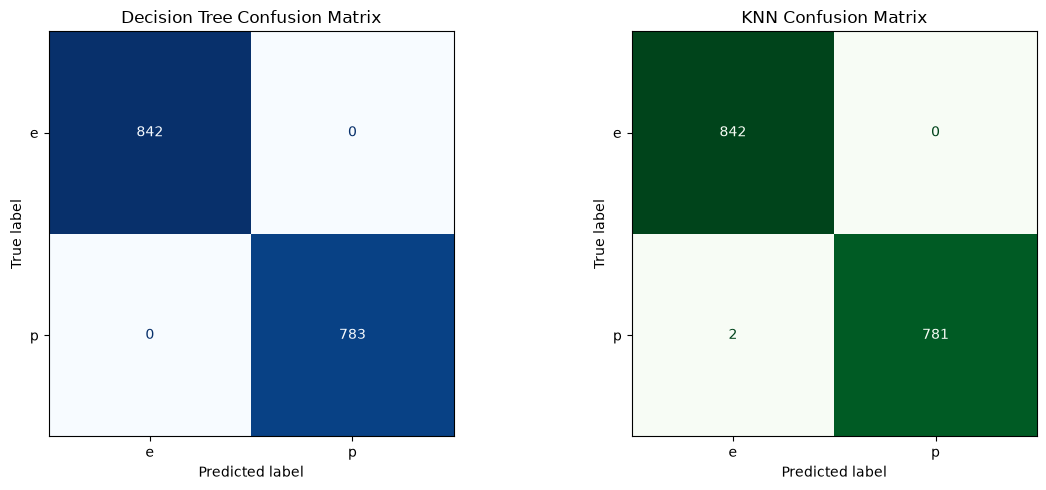

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_predictions,
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title("Decision Tree Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_predictions,
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)
axes[1].set_title("KNN Confusion Matrix")

plt.tight_layout()
plt.show()

In [8]:
if dt_accuracy > knn_accuracy:
    print("Decision Tree performed better on the test set.")
elif knn_accuracy > dt_accuracy:
    print("KNN performed better on the test set.")
else:
    print("Both models achieved the same test accuracy.")

print(f"Decision Tree accuracy: {dt_accuracy * 100:.2f}%")
print(f"KNN accuracy: {knn_accuracy * 100:.2f}%")

print("\nWhat I learned:")
print("1. How to load and inspect a real dataset.")
print("2. How to handle missing values and categorical features.")
print("3. How to train two classification models.")
print("4. How to compare accuracy and interpret confusion matrices.")

Decision Tree performed better on the test set.
Decision Tree accuracy: 100.00%
KNN accuracy: 99.88%

What I learned:
1. How to load and inspect a real dataset.
2. How to handle missing values and categorical features.
3. How to train two classification models.
4. How to compare accuracy and interpret confusion matrices.
